# Imports

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from cellpose import core, io, models

## Helper functions

In [9]:
def load_split(split_dir):
    """Load TIFF images and matching Cellpose *_seg.npy ground-truth masks."""
    image_paths = sorted(split_dir.glob("*.tif"))
    if not image_paths:
        raise FileNotFoundError(f"No .tif images found in {split_dir}")

    mask_paths = [split_dir / f"{image_path.stem}_seg.npy" for image_path in image_paths]
    missing_masks = [path for path in mask_paths if not path.is_file()]
    if missing_masks:
        raise FileNotFoundError(f"Missing ground-truth mask: {missing_masks[0]}")

    images = [io.imread(str(path)) for path in image_paths]
    labels = [np.load(path, allow_pickle=True).item()["masks"] for path in mask_paths]
    for image_path, image, label in zip(image_paths, images, labels):
        if image.shape[:2] != label.shape[:2]:
            raise ValueError(
                f"Image/mask shape mismatch for {image_path}: {image.shape} vs {label.shape}"
            )

    print(f"{split_dir.name}: loaded {len(images)} image/mask pairs")
    return images, labels, image_paths, mask_paths


def to_display(image):
    """Normalize a grayscale image for display."""
    image = np.asarray(image, dtype=np.float32)
    if image.ndim == 3 and image.shape[-1] == 1:
        image = image[..., 0]
    if image.ndim != 2:
        raise ValueError(f"Expected a 2D grayscale image, got shape {image.shape}")
    low, high = np.percentile(image, (1, 99))
    return np.clip((image - low) / (high - low + 1e-8), 0, 1)


def plot_predictions(images, predicted_masks, true_masks, image_paths):
    """Display each image beside its predicted mask and ground-truth mask."""
    n_images = len(images)
    if n_images == 0:
        raise ValueError("No images were provided for visualization")
    if not (n_images == len(predicted_masks) == len(true_masks) == len(image_paths)):
        raise ValueError("Images, predictions, labels, and paths must have equal lengths")

    fig, axes = plt.subplots(n_images, 3, figsize=(16, 4 * n_images), squeeze=False)
    titles = ("Input image", "Pretrained model prediction", "Ground truth")
    for row, (image, prediction, label, image_path) in enumerate(
        zip(images, predicted_masks, true_masks, image_paths)
    ):
        axes[row, 0].imshow(to_display(image), cmap="gray")
        axes[row, 0].set_ylabel(Path(image_path).name)
        axes[row, 1].imshow(prediction, cmap="nipy_spectral", interpolation="nearest")
        axes[row, 2].imshow(label, cmap="nipy_spectral", interpolation="nearest")
        for column, ax in enumerate(axes[row]):
            ax.set_xticks([])
            ax.set_yticks([])
            if row == 0:
                ax.set_title(titles[column])

    fig.tight_layout()
    plt.show()

## Load the prepared dataset

In [3]:
dataset_name = "A172_splits_n100_seed42"
data_dir_candidates = (Path("../data"), Path("cellpose/data"), Path("data"))
data_dir = next(
    (path for path in data_dir_candidates if (path / dataset_name).is_dir()),
    None,
)
if data_dir is None:
    raise FileNotFoundError(
        f"Could not find {dataset_name}; checked: {data_dir_candidates}"
    )
prepared_dir = data_dir / dataset_name

train_dir = prepared_dir / "train"
validation_dir = prepared_dir / "validation"
test_dir = prepared_dir / "test"

for split_dir in (train_dir, validation_dir, test_dir):
    if not split_dir.is_dir():
        raise FileNotFoundError(f"Prepared split directory not found: {split_dir.resolve()}")

print(f"Prepared dataset: {prepared_dir.resolve()}")

Prepared dataset: /storage/research/dsl_vibe_rs/trainings/2026_deep_learning_with_VIBE/cellpose/data/A172_splits_n100_seed42


In [8]:
train_data, train_labels, train_image_paths, train_mask_paths = load_split(train_dir)
validation_data, validation_labels, validation_image_paths, validation_mask_paths = load_split(validation_dir)
test_data, test_labels, test_image_paths, test_mask_paths = load_split(test_dir)

# These paired paths and arrays are ready for the training section below.
train_image_mask_paths = list(zip(train_image_paths, train_mask_paths))
validation_image_mask_paths = list(zip(validation_image_paths, validation_mask_paths))
test_image_mask_paths = list(zip(test_image_paths, test_mask_paths))

# print("Training image/mask paths:")
# for image_path, mask_path in train_image_mask_paths:
#     print(f"image: {image_path} | mask: {mask_path}")

train: loaded 80 image/mask pairs
validation: loaded 10 image/mask pairs
test: loaded 10 image/mask pairs


## Load the pretrained Cellpose-SAM model

In [5]:
io.logger_setup()
if not core.use_gpu():
    raise ImportError("No GPU access; use a VIBE instance with GPU support")

# Default pretrained model is cpsam_v2.
model = models.CellposeModel(gpu=True)
# Other available pretrained models can be selected here:
# model = models.CellposeModel(gpu=True, pretrained_model="cpdino")
# model = models.CellposeModel(gpu=True, pretrained_model="cpdino-vitb")

[GUI INFO] : WRITING LOG OUTPUT TO /storage/homefs/rl18y689/.cellpose/run.log

cellpose version: 	4.2.1.1 
platform:       	linux 
python version: 	3.13.15 
torch version:  	2.14.0+cu130
2026-10-22 14:27:25,054 [io INFO] WRITING LOG OUTPUT TO /storage/homefs/rl18y689/.cellpose/run.log
2026-10-22 14:27:25,054 [io INFO] 
cellpose version: 	4.2.1.1 
platform:       	linux 
python version: 	3.13.15 
torch version:  	2.14.0+cu130
2026-10-22 14:27:25,249 [core INFO] ** TORCH CUDA version installed and working. **
2026-10-22 14:27:25,250 [core INFO] ** TORCH CUDA version installed and working. **
2026-10-22 14:27:25,250 [core INFO] >>>> using GPU (CUDA)
2026-10-22 14:27:33,082 [models INFO] >>>> loading model /storage/homefs/rl18y689/.vibe/.cellpose/models/cpsam_v2


## Compare pretrained predictions with validation ground truth

This is a baseline from the default pretrained model, before fine-tuning it on this dataset.

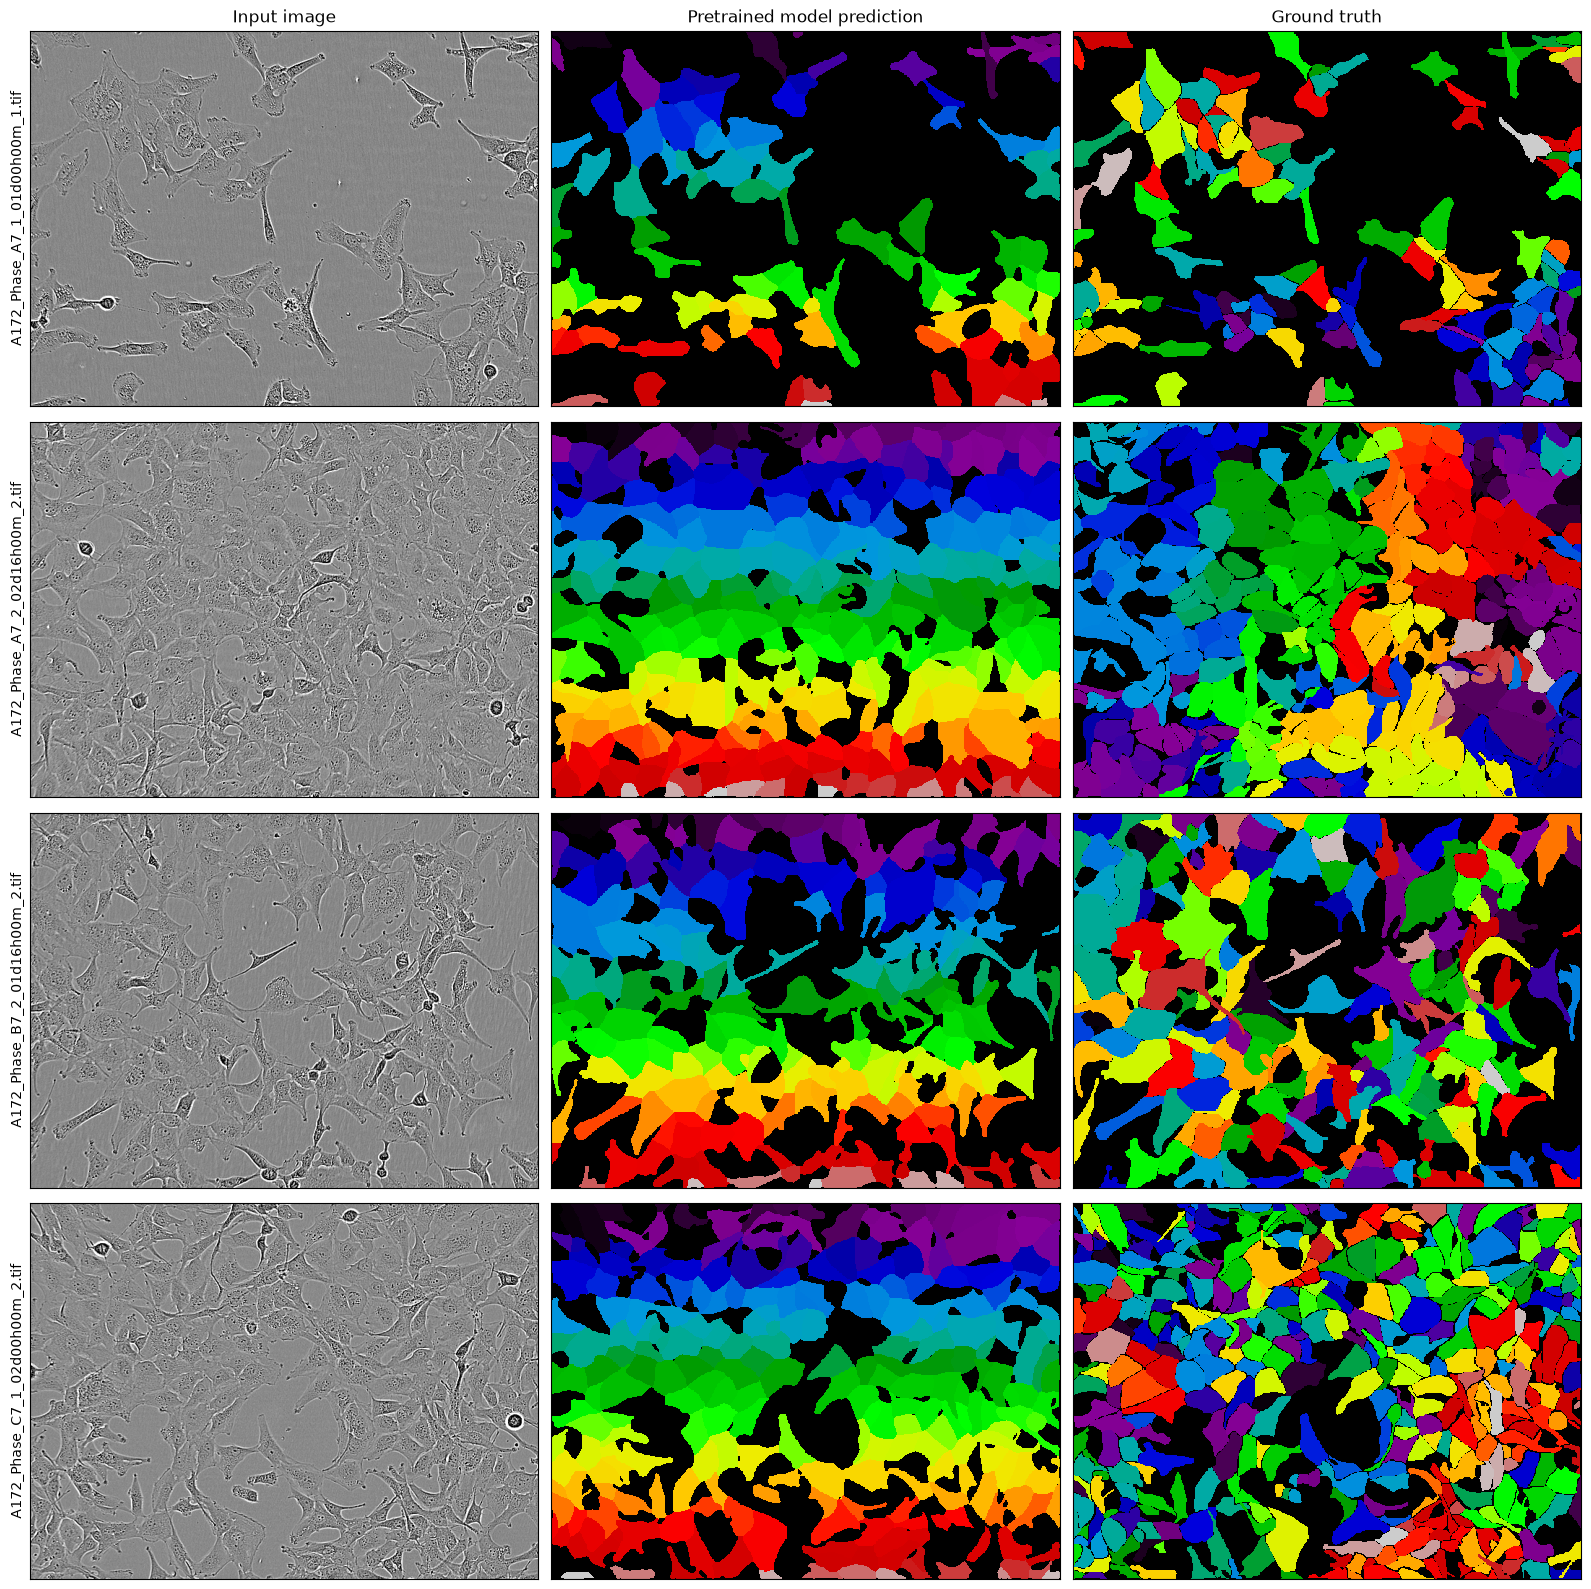

In [13]:
n_preview = min(4, len(validation_data))
validation_predictions = [model.eval(image)[0] for image in validation_data[:n_preview]]

plot_predictions(
    validation_data[:n_preview],
    validation_predictions,
    validation_labels[:n_preview],
    validation_image_paths[:n_preview],
)

## Train the model

Use `train_data` and `train_labels` for training, and `validation_data` and `validation_labels` for validation. Keep `test_data` and `test_labels` held out for final evaluation.